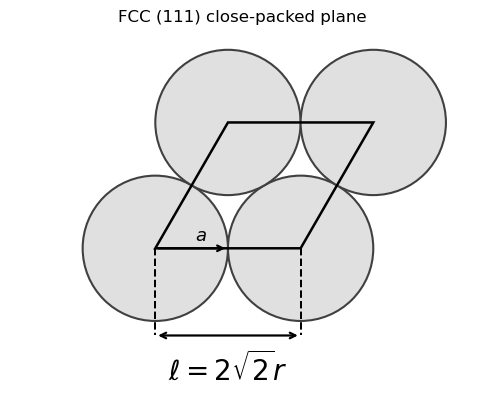

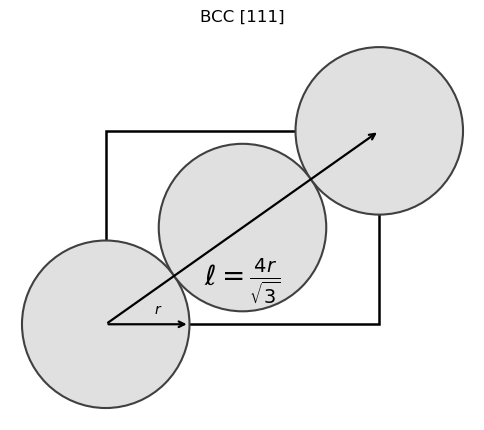

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon, Rectangle

CIRCLE_FACE = '0.88'
CIRCLE_EDGE = '0.25'
LW_ATOM     = 1.5
LW_OUTLINE  = 1.8
LW_ARROW    = 1.6
TITLE_PAD   = 10
FIGSIZE     = (6.0, 5.0)

# FCC (111) close-packed plane
def fcc_111(l):
    d = l/np.sqrt(2.0)
    r = d/2.0
    fig, ax = plt.subplots(figsize=FIGSIZE)

    # Circle (atom) centers
    centers = np.array([
        [0.0,      0.0],             
        [d,        0.0],             
        [0.5*d,  np.sqrt(3)/2*d],    
        [1.5*d,  np.sqrt(3)/2*d],    
    ])

    # Circles (atoms)
    for (cx, cy) in centers:
        ax.add_patch(Circle((cx, cy), r, facecolor=CIRCLE_FACE,
                            edgecolor=CIRCLE_EDGE, lw=LW_ATOM))

    # Rhombic 2D cell
    rh = np.array([
        [0.0, 0.0],
        [d, 0.0],
        [1.5*d, np.sqrt(3)/2*d],
        [0.5*d, np.sqrt(3)/2*d]
    ])
    ax.add_patch(Polygon(rh, fill=False, lw=LW_OUTLINE, edgecolor='black'))

    # Dimension arrow for l = 2 * sqrt(2) * r
    ydim = -0.6*d
    ax.annotate("", xy=(d, ydim), xytext=(0, ydim),
                arrowprops=dict(arrowstyle="<->", lw=LW_ARROW))
    ax.text(d/2, ydim-0.1*d, r"$ \ell = 2 \sqrt{2} r$", ha="center", va="top", size = 20)
    
    # dotted projection lines
    ax.plot([0, 0], [0, ydim], linestyle="--", linewidth=LW_OUTLINE*0.8, color = 'black')
    ax.plot([d, d], [0, ydim], linestyle="--", linewidth=LW_OUTLINE*0.8, color = 'black')

    # Radius arrow on the lower-left circle
    cx, cy = centers[0]
    ax.annotate("", xy=(cx + r, cy), xytext=(cx, cy),
                arrowprops=dict(arrowstyle="->", lw=LW_ARROW))
    ax.text(cx + 0.55*r, cy + 0.06*r, r"$a$", ha="left", va="bottom", size = 13)

    # Frame
    pad = 1.2*r
    ax.set_aspect('equal', 'box')
    ax.set_xlim(-d,  d + 2*pad)
    ax.set_ylim(-1.6*r, np.sqrt(3)/2*d + pad)
    ax.axis('off')
    ax.set_title("FCC (111) close-packed plane", pad=TITLE_PAD)
    plt.show()


# BCC [111]
def bcc_111(l):
    r = (np.sqrt(3.0)/4.0) * l         
    w = np.sqrt(2.0) * l                
    h = 1.0 * l                

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # Rectangle centered at origin
    ax.add_patch(Rectangle((-w/2, -h/2), w, h, fill=False,
                           lw=LW_OUTLINE, edgecolor='black'))

    # Circles along the body-diagonal projection: corner → center → opposite corner
    centers = np.array([[-w/2, -h/2], [0.0, 0.0], [w/2, h/2]])
    for cx, cy in centers:
        ax.add_patch(Circle((cx, cy), r, facecolor=CIRCLE_FACE,
                            edgecolor=CIRCLE_EDGE, lw=LW_ATOM))

    # Body-diagonal [111] arrow
    ax.annotate("", xy=(w/2, h/2), xytext=(-w/2, -h/2),
                arrowprops=dict(arrowstyle="->", lw=LW_ARROW))
    ax.text(0.0, -0.15*h, r"$\ell = \frac{4r} {\sqrt{3}} $", ha="center", va="top", size = 20)

    # Radius arrow on the lower-left circle
    ax.annotate("", xy=(-w/2 + r, -h/2), xytext=(-w/2, -h/2),
                arrowprops=dict(arrowstyle="->", lw=LW_ARROW))
    ax.text(-w/2 + 0.58*r, -h/2 + 0.10*r, r"$r$", ha="left", va="bottom")

    # Frame
    pad = 0.35 * w
    ax.set_aspect('equal', 'box')
    ax.set_xlim(-w/2 - pad, w/2 + pad)
    ax.set_ylim(-h/2 - pad, h/2 + pad)
    ax.axis('off')
    ax.set_title("BCC [111]", pad=10)
    plt.show()


fcc_111(l=1.0)
bcc_111(l=1.0)


Given a = 128.000 pm = 1.280 Å
FCC: l = 3.620387 Å = 0.362039 nm
Given a = 124.000 pm = 1.240 Å
BCC: l = 2.863657 Å = 0.286366 nm


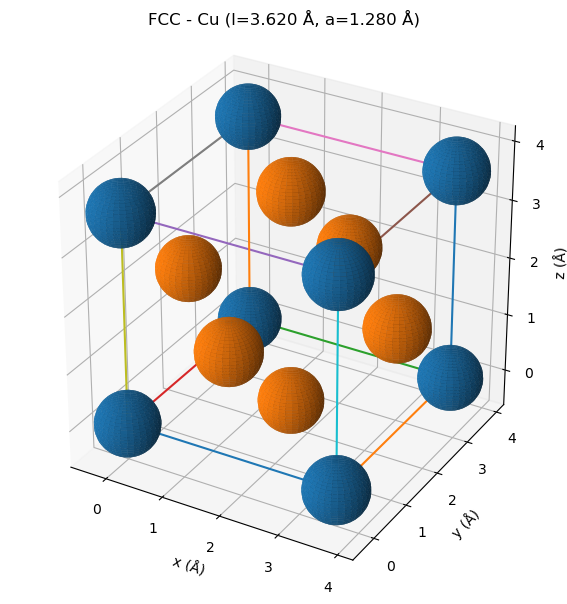

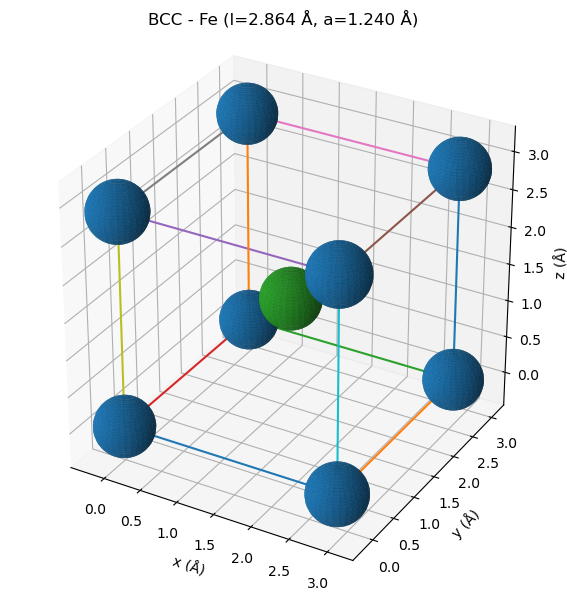

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# Parameters
a_Cu = 128.0              # atomic radius of Cu (pm)
a_Fe = 124.0              # atomic radius of Cu (pm)
BALL_SCALE_FCC = 0.40
BALL_SCALE_BCC = 0.30

# Units
pm_to_A = 0.01
A_to_nm = 0.1
r_A_Cu = a_Cu * pm_to_A
r_A_Fe = a_Fe * pm_to_A

# Lattice constants
l_fcc_A = 2.0*np.sqrt(2.0)*r_A_Cu          # FCC: l = 2√2 a
l_bcc_A = 4.0*r_A_Fe/np.sqrt(3.0)          # BCC: l = 4a/√3

print(f"Given a = {a_Cu:.3f} pm = {r_A_Cu:.3f} Å")
print(f"FCC: l = {l_fcc_A:.6f} Å = {l_fcc_A*A_to_nm:.6f} nm")
print(f"Given a = {a_Fe:.3f} pm = {r_A_Fe:.3f} Å")
print(f"BCC: l = {l_bcc_A:.6f} Å = {l_bcc_A*A_to_nm:.6f} nm")

def cube_edges():
    return [(0,1),(1,2),(2,3),(3,0),
            (4,5),(5,6),(6,7),(7,4),
            (0,4),(1,5),(2,6),(3,7)]

def corner_points(l_A):
    C = np.array([[0,0,0],[1,0,0],[1,1,0],[0,1,0],
                  [0,0,1],[1,0,1],[1,1,1],[0,1,1]], float)
    return C * l_A

def sphere(ax, center, radius, n=32, color=None, alpha=1.0):
    u = np.linspace(0, 2*np.pi, n); v = np.linspace(0, np.pi, n)
    x = center[0] + radius*np.outer(np.cos(u), np.sin(v))
    y = center[1] + radius*np.outer(np.sin(u), np.cos(v)*0 + np.sin(v))
    z = center[2] + radius*np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(x, y, z, linewidth=0, antialiased=True, shade=True,
                    color=color, alpha=alpha)

def draw_edges(ax, corners):
    for i,j in cube_edges():
        ax.plot([corners[i,0], corners[j,0]],
                [corners[i,1], corners[j,1]],
                [corners[i,2], corners[j,2]])

# FCC
def plot_fcc_balls(l_A, r_A_Cu, 
                   corner_c='tab:blue', face_c='tab:orange', scale=0.4):
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111, projection='3d')
    corners = corner_points(l_A)
    faces = np.array([[0.5,0.5,0.0],[0.5,0.5,1.0],
                      [0.5,0.0,0.5],[0.5,1.0,0.5],
                      [0.0,0.5,0.5],[1.0,0.5,0.5]]) * l_A
    draw_edges(ax, corners)
    for P in corners: sphere(ax, P, scale*r_A_Cu, color=corner_c)
    for P in faces:   sphere(ax, P, scale*r_A_Cu, color=face_c)
    ax.set_title(f'FCC - Cu (l={l_A:.3f} Å, a={r_A_Cu:.3f} Å)')
    ax.set_xlabel('x (Å)'); ax.set_ylabel('y (Å)'); ax.set_zlabel('z (Å)')
    disp_r = scale * r_A_Cu
    pad = 1.05 * disp_r
    ax.set_xlim(-pad, l_A + pad)
    ax.set_ylim(-pad, l_A + pad)
    ax.set_zlim(-pad, l_A + pad)
    try: ax.set_box_aspect((1,1,1))
    except: pass
    plt.tight_layout()
    plt.show()

# BCC
def plot_bcc_balls(l_A, r_A_Fe,
                   corner_c='tab:blue', center_c='tab:green', scale=0.3):
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111, projection='3d')
    corners = corner_points(l_A)
    body = np.array([[0.5,0.5,0.5]]) * l_A
    draw_edges(ax, corners)
    for P in corners: sphere(ax, P, scale*r_A_Fe, color=corner_c)
    for P in body:    sphere(ax, P, scale*r_A_Fe, color=center_c)
    ax.set_title(f'BCC - Fe (l={l_A:.3f} Å, a={r_A_Fe:.3f} Å)')
    ax.set_xlabel('x (Å)'); ax.set_ylabel('y (Å)'); ax.set_zlabel('z (Å)')
    disp_r = scale * r_A_Fe
    pad = 1.05 * disp_r
    ax.set_xlim(-pad, l_A + pad)
    ax.set_ylim(-pad, l_A + pad)
    ax.set_zlim(-pad, l_A + pad)
    try: ax.set_box_aspect((1,1,1))
    except: pass
    plt.tight_layout()
    plt.show()

# ----- Run -----
plot_fcc_balls(l_fcc_A, r_A_Cu, scale=BALL_SCALE_FCC)
plot_bcc_balls(l_bcc_A, r_A_Fe, scale=BALL_SCALE_BCC)

In [1]:
conda install conda-forge/label/cf202003::lammps

Solving environment: ...working... unsuccessful initial attempt using frozen solve. Retrying with flexible solve.
Solving environment: ...working... unsuccessful initial attempt using frozen solve. Retrying with flexible solve.

Note: you may need to restart the kernel to use updated packages.



PackagesNotFoundError: The following packages are not available from current channels:

  - conda-forge/label/cf202003::lammps

Current channels:

  - https://repo.anaconda.com/pkgs/main/win-64
  - https://repo.anaconda.com/pkgs/main/noarch
  - https://repo.anaconda.com/pkgs/r/win-64
  - https://repo.anaconda.com/pkgs/r/noarch
  - https://repo.anaconda.com/pkgs/msys2/win-64
  - https://repo.anaconda.com/pkgs/msys2/noarch

To search for alternate channels that may provide the conda package you're
looking for, navigate to

    https://anaconda.org

and use the search bar at the top of the page.


